# 03 Evaluate the LLM coding against the gold standard

Loads the coding runs and the manual annotation (gold standard): Krippendorff's α between runs and against the gold standard, confusion matrices, F1 per code, and an Excel export of false positives and false negatives for revising the codebook.

Cells tagged `api` call the LLM (OpenAI or Nebula) and were **not executed** for this repository. `dummy_data/` holds 12 synthetic citizen answers (plus 4 expert rows), random coding runs and random manual codings with the original file names. All results shown are meaningless.

In [1]:
# Folders. The original notebook read and wrote files in the project folder:
# DATA_DIR = OUT_DIR = "."
DATA_DIR = "dummy_data"   # synthetic example data shipped with this repo
OUT_DIR = "output"        # written by the notebook (gitignored)
import os; os.makedirs(OUT_DIR, exist_ok=True)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import MaxNLP
from pathlib import Path
import json
from tqdm.auto import tqdm

tqdm.pandas(desc="Applying")
%load_ext autoreload
%autoreload 2
    
from datetime import date
date_str = date.today().isoformat()

In [3]:
# Load the translated text sample (25 per country --> 250 samples)
df_t=pd.read_json(f"{DATA_DIR}/2026-05-02 new translated.json")

In [4]:
df_t[["QID5","QID8","QID10","QID15","QID19"]]

#questions=df_t[["QID5","QID8","QID10","QID15","QID19"]].iloc[0,:]
#df_t.loc["questions",["QID5","QID8","QID10","QID15","QID19"]]=questions
#df_t[["QID5","QID8","QID10","QID15","QID19"]].to_json(f"{OUT_DIR}/2026-04-29 Kaira Causes of the energy crisis.json")

,QID5,QID8,QID10,QID15,QID19
0,Can you name one specific example where the en...,What do you think caused the European energy c...,How do you think policymakers and other actors...,How did the energy crisis and the way it has b...,How do you think the experience of this crisis...
1,"{""ImportId"":""QID5_TEXT""}","{""ImportId"":""QID8_TEXT""}","{""ImportId"":""QID10_TEXT""}","{""ImportId"":""QID15_TEXT""}","{""ImportId"":""QID19_TEXT""}"
2,Ceny energii bardzo wzrosły.,I prezzi del gas sono aumentati molto.,De energierekening werd veel hoger.,De energierekening werd veel hoger.,Dependence on fossil fuels made Europe vulnera...
3,I don't know.,Companies made big profits while households pa...,De energierekening werd veel hoger.,Energy bills went up a lot after 2022.,Les prix de l'électricité ont beaucoup augmenté.
4,The EU should buy energy together.,Die Strompreise sind stark gestiegen.,Governments reacted too late.,The EU should buy energy together.,Energy bills went up a lot after 2022.
5,Die Strompreise sind stark gestiegen.,Companies made big profits while households pa...,Die Strompreise sind stark gestiegen.,The EU should buy energy together.,I prezzi del gas sono aumentati molto.
6,De energierekening werd veel hoger.,I don't know.,Dependence on fossil fuels made Europe vulnera...,Companies made big profits while households pa...,Governments reacted too late.
7,The EU should buy energy together.,Dependence on fossil fuels made Europe vulnera...,Dependence on fossil fuels made Europe vulnera...,De energierekening werd veel hoger.,Les prix de l'électricité ont beaucoup augmenté.
8,Dependence on fossil fuels made Europe vulnera...,I don't know.,We turned the heating down at home.,Dependence on fossil fuels made Europe vulnera...,Dependence on fossil fuels made Europe vulnera...
9,Energy bills went up a lot after 2022.,Les prix de l'électricité ont beaucoup augmenté.,Les prix de l'électricité ont beaucoup augmenté.,More solar and wind would help.,I don't know.


# Evaluation: small samples

In [5]:
codebook_name="causes"

import glob
import pandas as pd

#filelist=glob.glob(f"{DATA_DIR}/2026-05-06 causes_run_*.json")
filelist=glob.glob(f"{DATA_DIR}/2026-06-1* causes_run_*.json")

print(filelist)
x_runs=len(filelist)
files=[pd.read_json(file).drop_duplicates("orig_index").set_index("orig_index").ge(0.5).astype(int) for file in filelist]
x = pd.concat(files,
    keys=range(len(files)), names=["run"])


alphas = MaxNLP.kripp_alpha_all_variables(x, decimals=2)
print(alphas["krippendorff_alpha"].mean().round(3))
alphas

['dummy_data\\2026-06-10 causes_run_0_full.json', 'dummy_data\\2026-06-10 causes_run_1_full.json', 'dummy_data\\2026-06-10 causes_run_2_full.json', 'dummy_data\\2026-06-10 causes_run_3_full.json', 'dummy_data\\2026-06-11 causes_run_4_full.json']
0.568


,krippendorff_alpha,assessment
variable,,
EU sanctions against Russia,0.80,reliable
Industry and market actors,0.78,tentative reliability
Insufficient political efforts to make energy affordable,0.74,tentative reliability
Media actors,0.69,tentative reliability
EU political actors,0.68,tentative reliability
Too-fast energy transition,0.64,low reliability
Energy import dependence vulnerability,0.62,low reliability
National political actors,0.57,low reliability
Russia's war on Ukraine,0.55,low reliability


dummy_data/MANUAL CODING/2026-06-11 Disagreement manual code.xlsx DATE:  2026-11-06


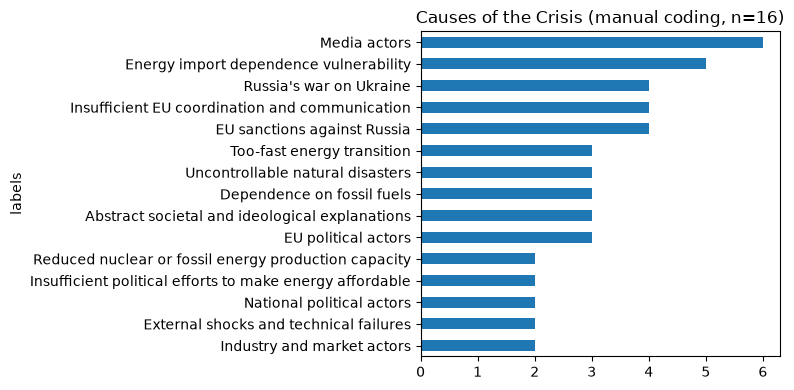

labels
Industry and market actors                                  2
External shocks and technical failures                      2
National political actors                                   2
Insufficient political efforts to make energy affordable    2
Reduced nuclear or fossil energy production capacity        2
EU political actors                                         3
Abstract societal and ideological explanations              3
Dependence on fossil fuels                                  3
Uncontrollable natural disasters                            3
Too-fast energy transition                                  3
EU sanctions against Russia                                 4
Insufficient EU coordination and communication              4
Russia's war on Ukraine                                     4
Energy import dependence vulnerability                      5
Media actors                                                6
dtype: int64


In [6]:
#Load Manual coding as gold standard
from pathlib import Path

Manual_coding_path=f"{DATA_DIR}/MANUAL CODING/2026-06-11 Disagreement manual code.xlsx"

print(Manual_coding_path, "DATE: ",pd.to_datetime(Path(Manual_coding_path).stat().st_mtime, unit="s").date())
Annotation=pd.read_excel(Manual_coding_path,header=0,index_col="labels").T


Text=Annotation.iloc[:,-4]

# remove the text, translation, and notes

# Drop columns with NaN column names and fill the rest of NA with 0 for this representation (code present = NO)
Annotation = Annotation.loc[:, Annotation.columns.notna()].apply(pd.to_numeric, errors='coerce').fillna(0)

# Then drop specific columns
Annotation = Annotation.drop(
    columns=['text', 'translation', 'Notes', 'SECOND_CODER'],  # 'SECOND_CODER': column named after the second human coder in the original file
    errors='ignore'
)


n_samples=Annotation.shape[0]

# plot the count in the manual annotation
s1 = Annotation.sum().sort_values()
s1.plot.barh(title=f"Causes of the Crisis (manual coding, n={n_samples})" , figsize=(8,4))
plt.tight_layout()
plt.show()
pd.set_option('display.max_colwidth', None)  # or a large number like 1000
print(s1)


In [7]:
# Get the mode (most common value from LLM code)
x_mode = x.groupby("orig_index").agg(lambda s: s.mode().iat[0]) # use the median

#x_mode = x.groupby("orig_index").agg(lambda s: s.iat[-1]) # use the last run

# Rename columns (when changed between runs during codebook development):
#x_mode.columns = x_mode.columns.str.replace("Slow energy transition / dependence on fossil fuels", 'Dependence on fossil fuels',    regex=True)


# Combine LLM & manual coding to one dataframe
merged = pd.concat(
    [x_mode.set_axis(x_mode.index.astype(int)).add_prefix("ai_"),
     Annotation.set_axis(Annotation.index.astype(int)).add_prefix("manual_")],
    axis=1,
    join="inner"
)

codes=x_mode.columns

per_topic = MaxNLP.eval_ai_vs_manual(merged, question_list=codes).round(2)
print(f'average F1 ({x_runs} runs):', per_topic[per_topic["N-pos"]>5].F1.mean().round(2))

per_topic.join(alphas["krippendorff_alpha"]).sort_values("F1", ascending=False)

average F1 (5 runs): 0.29


,N,N-pos,TP,FP,TN,FN,Precision,Recall,F1,F-beta,krippendorff_alpha
Too-fast energy transition,16.0,3.0,2.0,3.0,10.0,1.0,0.40,0.67,0.50,0.75,0.64
Energy import dependence vulnerability,16.0,5.0,2.0,3.0,8.0,3.0,0.40,0.40,0.40,0.62,0.62
Dependence on fossil fuels,16.0,3.0,1.0,1.0,12.0,2.0,0.50,0.33,0.40,0.81,0.47
National political actors,16.0,2.0,1.0,2.0,12.0,1.0,0.33,0.50,0.40,0.81,0.57
Uncontrollable natural disasters,16.0,3.0,1.0,1.0,12.0,2.0,0.50,0.33,0.40,0.81,0.50
Insufficient EU coordination and communication,16.0,4.0,1.0,1.0,11.0,3.0,0.50,0.25,0.33,0.75,0.37
Media actors,16.0,6.0,1.0,0.0,10.0,5.0,1.00,0.17,0.29,0.69,0.69
EU sanctions against Russia,16.0,4.0,1.0,4.0,8.0,3.0,0.20,0.25,0.22,0.56,0.80
External shocks and technical failures,16.0,2.0,0.0,1.0,13.0,2.0,0.00,0.00,0.00,0.81,0.29
Abstract societal and ideological explanations,16.0,3.0,0.0,2.0,11.0,3.0,0.00,0.00,0.00,0.69,0.54


In [8]:
# Create Disagreement dataframes for analysis: total disagreement, FP & FN

focus_label="Russia's war on Ukraine"

disagree_df = pd.DataFrame({c: merged[f"ai_{c}"] != merged[f"manual_{c}"]  for c in codes}, index=merged.index)
fp_df = pd.DataFrame({c: (merged[f"ai_{c}"]==1) & (merged[f"manual_{c}"]==0)  for c in codes}, index=merged.index)
fn_df = pd.DataFrame({c: (merged[f"ai_{c}"]==0) & (merged[f"manual_{c}"]==1)  for c in codes}, index=merged.index)
df_t.loc[fn_df[focus_label],"QID8_en"].to_list() 

AssertionError: 

In [9]:
# Create excel with colored disagreements.
Annotation=pd.read_excel(f"{DATA_DIR}/MANUAL CODING/2026-06-09c Disagreement manual code.xlsx",header=0,index_col="labels").T

#!pip install XlsxWriter             
MaxNLP.write_disagreement_excel(
    annotation_df=Annotation,
    merged_df=merged,
    codes=codes,
    path=f"{DATA_DIR}/MANUAL CODING/2026-06-11b Disagreement manual code.xlsx"
)

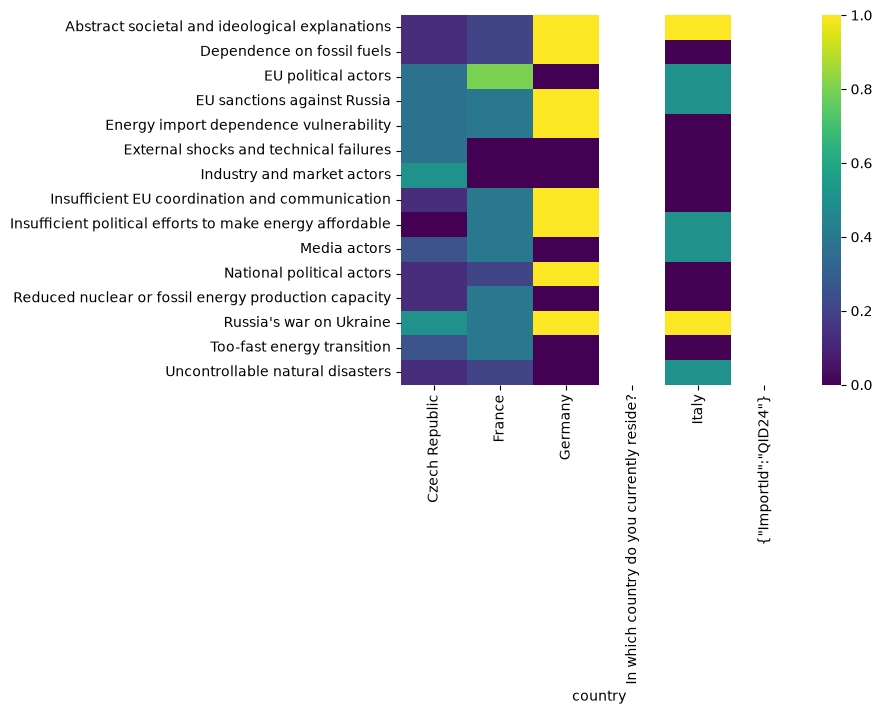

In [10]:
# Visualize disagreements

import seaborn as sns
cols = [c.replace('manual_','') for c in merged.columns if c.startswith('manual_') and f'ai_{c.replace("manual_","")}' in merged.columns]
disagree = merged[[f'ai_{c}' for c in cols]].astype(int).ne(merged[[f'manual_{c}' for c in cols]].astype(int).set_axis([f'ai_{c}' for c in cols], axis=1)).set_axis(cols, axis=1)
df_country = (df_t[['country']].join(disagree).groupby('country', dropna=False).mean().round(2).astype(float))
sns.heatmap(df_country.T, cmap='viridis'); 



<Axes: title={'center': 'Counts in the LLM coding'}>

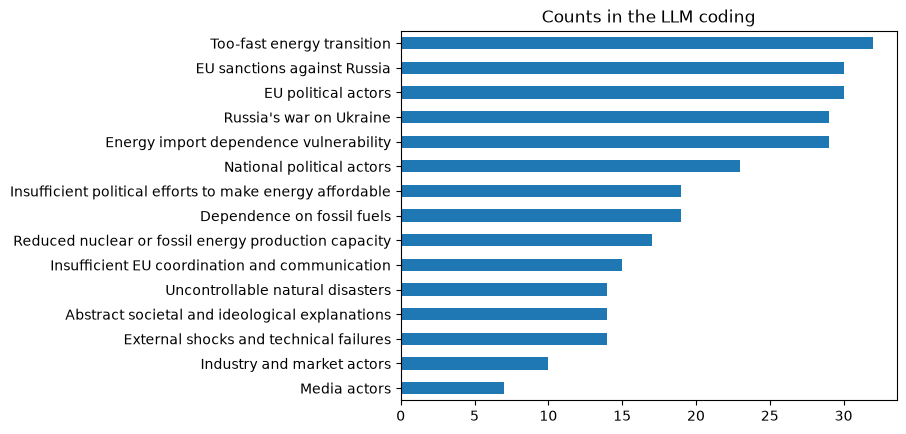

In [11]:
x.sum().sort_values().plot.barh(title="Counts in the LLM coding")

    meaning=texts["QID5"]
    causes=texts["QID8"]
    response=texts["QID10"]
    consequence=texts["QID15"]
    moral=texts["QID19"]